# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Недосіка Назарій Вадимович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 14      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 14, файл lr6_варіант_14.csv


In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

встановлюю: shap ...
усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
TYPE_OF_TASK = 'класифікація'
# чому: передбачаємо не число, а один із двох відомих класів (піде / не піде), і в даних є правильні відповіді — колонка «відтік».

METRIC = 'AUC'
# чому саме ця, а не точність: відтоку лише 15–30 %, тож модель «ніхто не піде» має точність 70–85 % і нульову користь, а її AUC = 0.5, тобто марність одразу видно; до того ж AUC не залежить від порогу, який потім обере бізнес.

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'
# чому саме така: стратифікація зберігає однакову частку відтоку в кожній згортці, а 4 повтори (20 навчань) дають середнє ± розкид, бо на 1200 рядках одне число з одного поділу залежало б від випадку.

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.258

типи стовпців: {'str': 14, 'float64': 7, 'int64': 5}


In [6]:
info = pd.DataFrame({
    'тип':          raw.dtypes.astype(str),
    'унікальних':   raw.nunique(),
    '% пропусків':  (raw.isna().mean() * 100).round(1),
    'приклад':      [raw[c].dropna().iloc[0] if raw[c].notna().any() else None
                     for c in raw.columns],
}).sort_values('% пропусків', ascending=False)

display(info)

,тип,унікальних,% пропусків,приклад
дата_розірвання,str,273,74.2,2024-12-14
код_причини_закриття,str,5,74.2,ПЕР-04
середній_час_відповіді_хв,float64,265,32.3,12.2
трафік_ГБ,str,958,5.0,91.8
щомісячний_платіж,str,1125,4.0,261.71
аварій_на_ділянці_за_квартал,float64,6,3.0,3.0
стать,str,6,0.0,ч
місто,str,6,0.0,Львів
id_клієнта,str,1200,0.0,K140000
вік,float64,61,0.0,33.0


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [ ]:
s = raw['щомісячний_платіж'].dropna().astype(str)
print('Текст у щомісячний_платіж:')
print(s[~s.str.fullmatch(r'-?\d+(\.\d+)?')].head())

t = raw['трафік_ГБ'].dropna().astype(str)
print('\nДати у трафік_ГБ:')
print(t[t.str.contains('1900-')])

print('\nЧастка пропусків у середній_час_відповіді_хв за кількістю звернень:')
print(raw['середній_час_відповіді_хв'].isna()
         .groupby(raw['кількість_звернень_у_підтримку']).mean())

Текст у щомісячний_платіж:
50     327.41 грн
83     381.89 грн
88     590.24 грн
144    293.07 грн
270     324.0 грн
Name: щомісячний_платіж, dtype: str

Дати у трафік_ГБ:
6       1900-01-07 00:00:00
592     1900-01-05 00:00:00
1122    1900-01-03 00:00:00
Name: трафік_ГБ, dtype: str

Частка пропусків у середній_час_відповіді_хв за кількістю звернень:
кількість_звернень_у_підтримку
0    1.0
1    0.0
2    0.0
3    0.0
4    0.0
5    0.0
6    0.0
Name: середній_час_відповіді_хв, dtype: float64


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'
PROBLEM_MNAR           = 'середній_час_відповіді_хв'
MNAR_MEANING           = 'пропуск означає, що клієнт жодного разу не звертався в підтримку (кількість звернень = 0), тому часу відповіді просто не існує'

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    def one(v):
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return np.nan
        if isinstance(v, (datetime.datetime, datetime.date, pd.Timestamp)):
            return np.nan
        if isinstance(v, (int, float, np.integer, np.floating)):
            return float(v)
        txt = str(v).strip()
        if re.match(r'^\d{4}-\d{2}-\d{2}', txt):
            return np.nan
        m = re.match(r'-?\d+(?:[.,]\d+)?', txt)
        if m is None:
            return np.nan
        return float(m.group().replace(',', '.'))
    return s.map(one)


_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']
SYNONYMS = {'чол': 'ч', 'жін': 'ж'}

def build_X(d, drop):
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        col = d[c]
        if c.startswith('дата_'):
            dt = pd.to_datetime(col, errors='coerce')
            X[c] = (dt - pd.Timestamp('2000-01-01')).dt.days.astype(float)
            log.append({'стовпець': c, 'рішення': 'дата -> число', 'деталі': 'днів від 2000-01-01'})
        elif pd.api.types.is_numeric_dtype(col):
            X[c] = col.astype(float)
            log.append({'стовпець': c, 'рішення': 'число', 'деталі': ''})
        else:
            num = to_number(col)
            share = num.notna().sum() / col.notna().sum()
            if share > 0.8:
                X[c] = num
                log.append({'стовпець': c, 'рішення': 'текст -> число',
                            'деталі': 'розібрано %.1f%%' % (share * 100)})
            else:
                clean = col.astype(str).str.strip().str.lower().replace(SYNONYMS).where(col.notna())
                X[c] = clean.astype('category')
                log.append({'стовпець': c, 'рішення': 'категорія',
                            'деталі': '%d рівнів' % X[c].nunique()})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 9


,стовпець,рішення,деталі
0,вік,число,
1,стать,категорія,2 рівнів
2,місто,категорія,6 рівнів
3,філія,категорія,6 рівнів
4,тариф,категорія,4 рівнів
5,тип_підключення,категорія,3 рівнів
6,спосіб_оплати,категорія,3 рівнів
7,автоплатіж,категорія,2 рівнів
8,кількість_послуг,число,
9,місяців_обслуговування,число,


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [23]:
def make_pipe(X, clf):
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    num = [c for c in X.columns if c not in cat]
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
    ])
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.995


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.994 ± 0.003
час      : 0.8 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = 'AUC ≈ 0.99 означає, що модель майже завжди ставить клієнта, який пішов, вище за того, хто лишився; на реальних даних про відтік так не буває, тож це не «легка задача», а майже напевно витік — у таблиці є колонки, записані вже після розірвання договору (напр. дата_розірвання, код_причини_закриття).'
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC ≈ 0.99 означає, що модель майже завжди ставить клієнта, який пішов, вище за того, хто лишився; на реальних даних про відтік так не буває, тож це не «легка задача», а майже напевно витік — у таблиці є колонки, записані вже після розірвання договору (напр. дата_розірвання, код_причини_закриття).


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        n_filled, n_empty = filled.sum(), (~filled).sum()
        if n_filled > min_group and n_empty > min_group:
            score = roc_auc_score(y, filled.astype(int))
            score = max(score, 1 - score)
        else:
            score = np.nan
        rows.append({'ознака': c, 'заповнено': int(n_filled),
                     'частка_відтоку_де_заповнено': y[filled].mean() if n_filled else np.nan,
                     'частка_відтоку_де_пропуск': y[~filled].mean() if n_empty else np.nan,
                     'показник': score})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,код_причини_закриття,310,1.000000,0.000000,1.000000
23,дата_розірвання,310,1.000000,0.000000,1.000000
17,середній_час_відповіді_хв,812,0.270936,0.231959,0.522254
14,трафік_ГБ,1140,0.261404,0.200000,0.507611
16,аварій_на_ділянці_за_квартал,1164,0.256014,0.333333,0.505872
12,щомісячний_платіж,1152,0.260417,0.208333,0.505219
0,id_клієнта,1200,0.258333,NaN,NaN
1,вік,1200,0.258333,NaN,NaN
2,стать,1200,0.258333,NaN,NaN
3,місто,1200,0.258333,NaN,NaN


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'дата_розірвання',
    'код_причини_закриття',
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['дата_розірвання', 'код_причини_закриття']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.977 ± 0.006


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'код_тарифного_плану', 'скоринг_партнера', 'дата_підключення', 'оцінка_ризику_менеджером']


In [18]:
HUMAN_LEAK = [
    'оцінка_ризику_менеджером',
]
HUMAN_LEAK_WHY = 'детектор перевіряє лише, чи заповнена колонка, а ця оцінка заповнена в усіх клієнтів (0 % пропусків), тож заповненість нічого не каже; витік сидить у самих значеннях — це вже готовий прогноз людини, яка знала, чим усе скінчиться'

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.863 ± 0.023


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

                 mean  size
філія                      
Ф-01 Центр      0.465   198
Ф-02 Захід      0.382   170
Ф-03 Схід       0.169   231
Ф-04 Південь    0.181   182
Ф-05 Північ     0.206   209
Ф-06 Приміська  0.181   210
                   mean  size
дата_підключення             
2023Q1            0.205   156
2023Q2            0.301   153
2023Q3            0.278   158
2023Q4            0.275   153
2024Q1            0.271   140
2024Q2            0.243   140
2024Q3            0.250   144
2024Q4            0.244   156


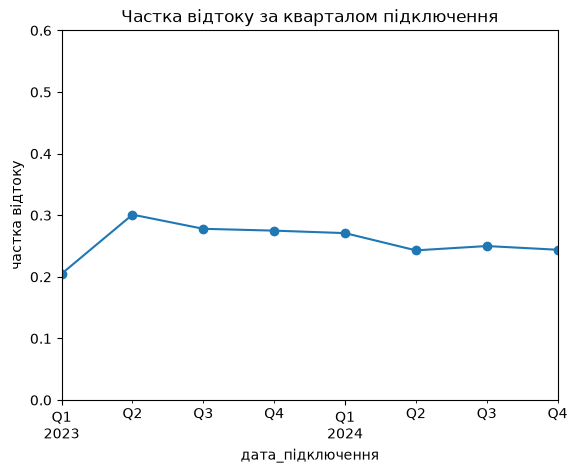

In [19]:
print(raw.groupby('філія')[TARGET].agg(['mean', 'size']).round(3))

q = pd.to_datetime(raw['дата_підключення'], errors='coerce').dt.to_period('Q')
by_q = raw.groupby(q)[TARGET].agg(['mean', 'size']).round(3)
print(by_q)

by_q['mean'].plot(marker='o', title='Частка відтоку за кварталом підключення')
plt.ylabel('частка відтоку'); plt.ylim(0, 0.6); plt.show()

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'філія'
assert SUSPECT in ('філія', 'дата_підключення')

source = raw['філія'].isin(['Ф-01 Центр', 'Ф-02 Захід']).astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.700
ті самі ознаки передбачають ВІДТІК  : AUC 0.819 ± 0.022


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.994
2. мінус цільовий витік,22,0.977
3. мінус оцінки людини,21,0.863
4. мінус артефакт збору,20,0.819


чесне число: 0.819 ± 0.022


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'залишити, але звітувати окремо'
DECISION_WHY = 'відтік у Ф-01 Центр і Ф-02 Захід (46.5 % і 38.2 %) у 2–2.5 раза вищий, ніж в інших філіях (17–21 %), а ознаки без філії все одно вгадують цю групу з AUC 0.70 — схоже на інше правило обліку; але різниця може бути й справжньою (більше конкурентів у центрі), тому чесне число рахую без філії (AUC 0.819), а якість на цих двох філіях звітую окремо і не переношу модель на нові філії без перевірки'
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

залишити, але звітувати окремо — відтік у Ф-01 Центр і Ф-02 Захід (46.5 % і 38.2 %) у 2–2.5 раза вищий, ніж в інших філіях (17–21 %), а ознаки без філії все одно вгадують цю групу з AUC 0.70 — схоже на інше правило обліку; але різниця може бути й справжньою (більше конкурентів у центрі), тому чесне число рахую без філії (AUC 0.819), а якість на цих двох філіях звітую окремо і не переношу модель на нові філії без перевірки


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [24]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                   n_jobs=-1, random_state=SEED),
    'гістограмний бустинг': HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                                                           max_depth=3, random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.819,0.022,0.9
одне дерево,0.748,0.037,0.8
випадковий ліс,0.835,0.021,9.4
гістограмний бустинг,0.839,0.024,3.7


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [25]:
from scipy import stats

def paired(a, b):
    d = np.asarray(b) - np.asarray(a)
    n = len(d)
    h = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
    return d.mean(), h


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0166 ± 0.0093   значуще
гістограмний бустинг   проти логістичної: +0.0199 ± 0.0090   значуще


In [26]:
CHOSEN_MODEL = 'гістограмний бустинг'
CHOSEN_WHY = 'якість: найвищий AUC 0.839, приріст +0.020 ± 0.009 над логістичною значущий; стабільність: розкид 0.024, як у інших; швидкість: ~4 с проти ~10 с у лісу; зрозумілість: гірша за логістичну, але пояснення дасть SHAP у частині 2'
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: гістограмний бустинг — якість: найвищий AUC 0.839, приріст +0.020 ± 0.009 над логістичною значущий; стабільність: розкид 0.024, як у інших; швидкість: ~4 с проти ~10 с у лісу; зрозумілість: гірша за логістичну, але пояснення дасть SHAP у частині 2


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [27]:
def add_features(X):
    F = X.copy()
    # переплата: хто платить багато за малу швидкість, той шукає дешевшого провайдера
    F['переплата_грн_за_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']
    # трафік на гривню: хто мало користується послугою за свої гроші, тому вона не потрібна, і він іде
    F['ГБ_на_гривню'] = F['трафік_ГБ'] / F['щомісячний_платіж']
    # звернення на місяць: 3 звернення за 2 місяці гірше, ніж 3 за 5 років; частота проблем важить більше за кількість
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
    # чи є знижка взагалі: може, важить сам факт знижки, а не її розмір
    F['є_знижка'] = (F['знижка_відсоток'] > 0).astype(float)
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 24


In [ ]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL = 'складніша модель дала більше: гістограмний бустинг +0.020 ± 0.009 над логістичною (≈4 с проти ≈0.6 с на 20 навчань), а чотири сконструйовані ознаки дали -0.0025 ± 0.0015 при тому самому часі ≈0.6 с — вони лише перекомбінували колонки, які модель уже бачила, і нового сигналу не додали'
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

складніша модель дала більше: гістограмний бустинг +0.020 ± 0.009 над логістичною (≈4 с проти ≈0.6 с на 20 навчань), а чотири сконструйовані ознаки дали -0.0025 ± 0.0015 при тому самому часі ≈0.6 с — вони лише перекомбінували колонки, які модель уже бачила, і нового сигналу не додали


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.830
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

,вбудована важливість
щомісячний_платіж,0.096072
код_тарифного_плану,0.095723
ГБ_на_гривню,0.087783
вік,0.070699
переплата_грн_за_Мбіт,0.063009
місяців_обслуговування,0.058461
трафік_МБ,0.057522
трафік_ГБ,0.055193
швидкість_тарифу_Мбіт,0.053375
дата_підключення,0.043304


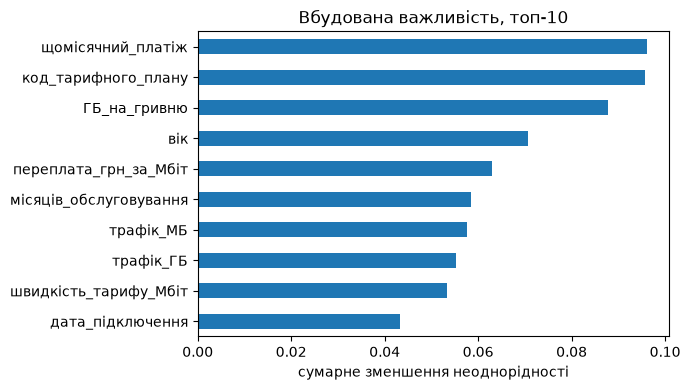

In [30]:
names = model.named_steps['prep'].get_feature_names_out()
raw_imp = pd.Series(model.named_steps['clf'].feature_importances_, index=names)
cat_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) == 'category']

def orig(n):
    n = n.split('__', 1)[1]
    for c in cat_cols:
        if n.startswith(c + '_'):
            return c
    return n

gini_imp = raw_imp.groupby(orig).sum().sort_values(ascending=False)
display(gini_imp.head(10).to_frame('вбудована важливість'))

gini_imp.head(10)[::-1].plot.barh(figsize=(7, 4), title='Вбудована важливість, топ-10')
plt.xlabel('сумарне зменшення неоднорідності')
plt.tight_layout(); plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.043818
щомісячний_платіж,0.041942
ГБ_на_гривню,0.035432
місяців_обслуговування,0.030726
звернень_на_місяць,0.013501
швидкість_тарифу_Мбіт,0.009422
спосіб_оплати,0.007358
аварій_на_ділянці_за_квартал,0.005920
автоплатіж,0.003248
кількість_послуг,0.002859


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
cmp_imp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp})
cmp_imp = cmp_imp.sort_values('вбудована', ascending=False).round(4)
display(cmp_imp)

,вбудована,перестановочна
щомісячний_платіж,0.0961,0.0419
код_тарифного_плану,0.0957,-0.0009
ГБ_на_гривню,0.0878,0.0354
вік,0.0707,0.0438
переплата_грн_за_Мбіт,0.0630,0.0016
місяців_обслуговування,0.0585,0.0307
трафік_МБ,0.0575,0.0027
трафік_ГБ,0.0552,-0.0002
швидкість_тарифу_Мбіт,0.0534,0.0094
дата_підключення,0.0433,0.0015


In [33]:
FAKE_IMPORTANT = 'код_тарифного_плану'
FAKE_IMPORTANT_WHY = 'у вбудованій важливості він на 2-му місці (0.096), а перестановочна ≈ 0 (-0.0009): ознака має 40 рівнів, після одиничного кодування це 40 колонок, і на кожній ліс може зробити розбиття, яке на навчальних даних трохи зменшує неоднорідність (особливо відокремлюючи кілька клієнтів рідкісного коду); сумарно це дає велике число, але це запам\'ятовування шуму — на перевірковій частині перемішування коду якість не погіршує'
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: код_тарифного_плану


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
num = FINAL_X.select_dtypes('number')
corr = num.corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
display(pairs[pairs > 0.97].sort_values(ascending=False).to_frame('|r|'))

,,|r|
трафік_ГБ,трафік_МБ,0.999723


In [35]:
DUP_PAIR = ['трафік_МБ', 'трафік_ГБ']
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

X_nodup = FINAL_X.drop(columns=[DUP_PAIR[1]])
Xtr_d, Xte_d, ytr_d, yte_d = train_test_split(X_nodup, y, test_size=0.3,
                                              stratify=y, random_state=SEED)
model_d = make_pipe(X_nodup, RandomForestClassifier(n_estimators=300, random_state=SEED,
                                                    n_jobs=-1)).fit(Xtr_d, ytr_d)
perm_d = permutation_importance(model_d, Xte_d, yte_d, n_repeats=10,
                                random_state=SEED, scoring='roc_auc')
perm_d = pd.Series(perm_d.importances_mean, index=X_nodup.columns)
print('без пари:')
print('   %-28s %+.4f' % (DUP_PAIR[0], perm_d[DUP_PAIR[0]]))

у повній моделі:
   трафік_МБ                    +0.0027
   трафік_ГБ                    -0.0002
без пари:
   трафік_МБ                    +0.0098


In [36]:
DUP_EXPLANATION = 'трафік_ГБ і трафік_МБ — це одна величина (|r| = 0.9997); коли перемішуємо одну, модель бере ту саму інформацію з другої, тож якість майже не падає і обидві виглядають непотрібними (+0.0027 і -0.0002); коли ГБ прибрали, МБ лишився єдиним джерелом трафіку і його важливість зросла до +0.0098; перестановочна важливість відповідає на питання «наскільки гірше без ЦІЄЇ ознаки, коли решта на місці», тож висновок «важливість ≈ 0, отже ознаку можна викинути» хибний — викидати можна лише одну з дублів, не обидві'
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

трафік_ГБ і трафік_МБ — це одна величина (|r| = 0.9997); коли перемішуємо одну, модель бере ту саму інформацію з другої, тож якість майже не падає і обидві виглядають непотрібними (+0.0027 і -0.0002); коли ГБ прибрали, МБ лишився єдиним джерелом трафіку і його важливість зросла до +0.0098; перестановочна важливість відповідає на питання «наскільки гірше без ЦІЄЇ ознаки, коли решта на місці», тож висновок «важливість ≈ 0, отже ознаку можна викинути» хибний — викидати можна лише одну з дублів, не обидві


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

топ-3 числові: ['вік', 'щомісячний_платіж', 'ГБ_на_гривню']


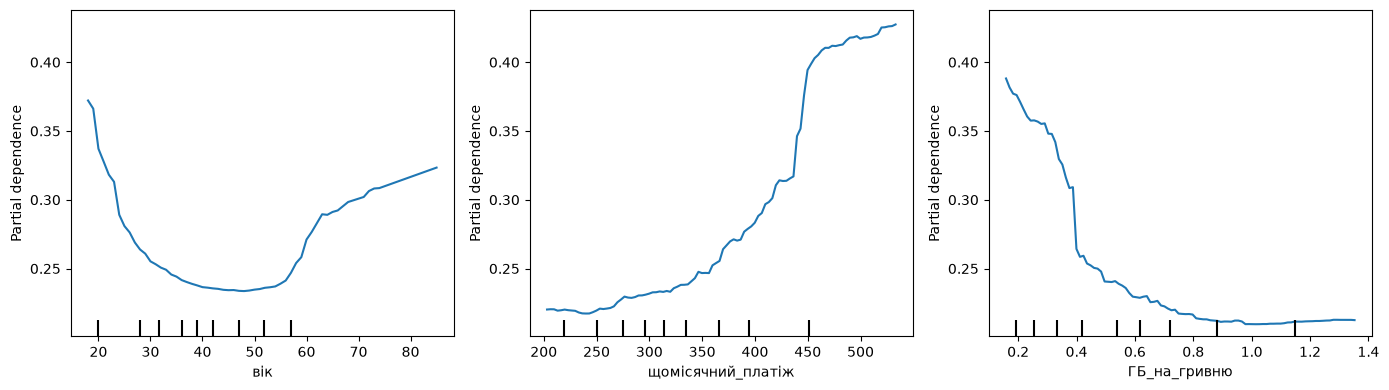

In [37]:
from sklearn.inspection import PartialDependenceDisplay

num_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
top3 = [c for c in perm_imp.index if c in num_cols][:3]
print('топ-3 числові:', top3)

X_pdp = Xte.dropna(subset=top3)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
PartialDependenceDisplay.from_estimator(model, X_pdp, features=top3, kind='average', ax=ax)
plt.tight_layout(); plt.show()

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

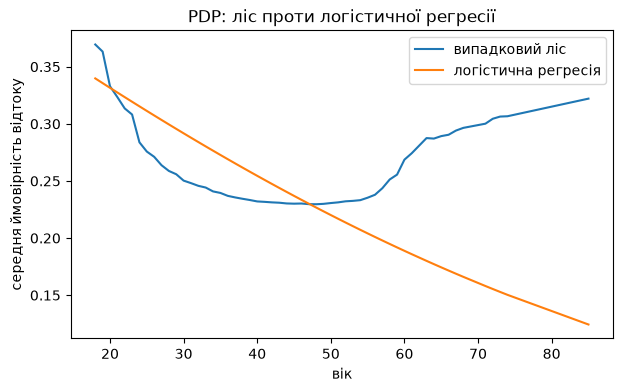

In [38]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

model_lr = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)

fig, ax = plt.subplots(figsize=(7, 4))
for mdl, label in [(model, 'випадковий ліс'), (model_lr, 'логістична регресія')]:
    pd_res = partial_dependence(mdl, Xte, [NONLINEAR_FEATURE], kind='average')
    ax.plot(pd_res['grid_values'][0], pd_res['average'][0], label=label)
ax.set_xlabel(NONLINEAR_FEATURE)
ax.set_ylabel('середня ймовірність відтоку')
ax.set_title('PDP: ліс проти логістичної регресії')
ax.legend(); plt.show()

In [39]:
NONLINEAR_MEANING = 'найчастіше йдуть наймолодші (до ~25 років: часто переїжджають, шукають дешевше, легко міняють провайдера) і найстарші клієнти (65+: переїзд до родичів, відмова від послуги), а люди середнього віку 35–55 найстабільніші — у них сім\'я, житло, звичка; ризик спадає з віком, а після ~55 знову росте'
NONLINEAR_FIX = 'квадрат відхилення віку від «найбезпечнішого» віку: (вік − 45)²; він малий для середнього віку і великий для обох країв, тож лінійна модель одним додатним коефіцієнтом при ньому опише U-форму'
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

найчастіше йдуть наймолодші (до ~25 років: часто переїжджають, шукають дешевше, легко міняють провайдера) і найстарші клієнти (65+: переїзд до родичів, відмова від послуги), а люди середнього віку 35–55 найстабільніші — у них сім'я, житло, звичка; ризик спадає з віком, а після ~55 знову росте
квадрат відхилення віку від «найбезпечнішого» віку: (вік − 45)²; він малий для середнього віку і великий для обох країв, тож лінійна модель одним додатним коефіцієнтом при ньому опише U-форму


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
pd_age = partial_dependence(model, Xte, [NONLINEAR_FEATURE], kind='average')
best_age = float(pd_age['grid_values'][0][np.argmin(pd_age['average'][0])])
print('мінімальний ризик при віці:', best_age)

X_quad = FINAL_X.copy()
X_quad['вік_відхилення_кв'] = (X_quad[NONLINEAR_FEATURE] - best_age) ** 2

auc_lr_base = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
auc_lr_quad = cross_val_score(make_pipe(X_quad, logreg()), X_quad, y, cv=cv, scoring='roc_auc')
m, h = paired(auc_lr_base, auc_lr_quad)
print('логістична без ознаки: %.3f, з ознакою: %.3f' % (auc_lr_base.mean(), auc_lr_quad.mean()))
print('приріст: %+0.4f ± %.4f   %s' % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

мінімальний ризик при віці: 48.0
логістична без ознаки: 0.816, з ознакою: 0.855
приріст: +0.0385 ± 0.0075   значуще


In [41]:
QUAD_GAIN = float(m)
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0385


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

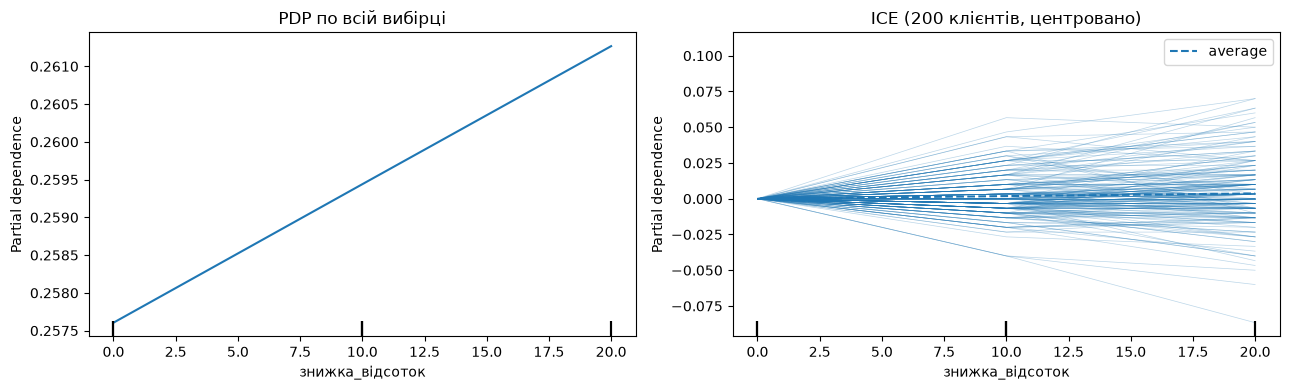

In [42]:
from sklearn.inspection import PartialDependenceDisplay

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'],
                                        kind='average', ax=ax[0])
ax[0].set_title('PDP по всій вибірці')
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'],
                                        kind='both', centered=True, subsample=200,
                                        random_state=SEED, ax=ax[1])
ax[1].set_title('ICE (200 клієнтів, центровано)')
plt.tight_layout(); plt.show()

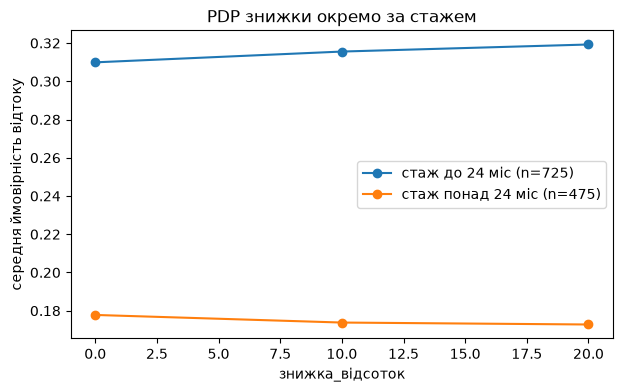

In [43]:
short = FINAL_X['місяців_обслуговування'] <= 24
long_ = FINAL_X['місяців_обслуговування'] > 24

fig, ax = plt.subplots(figsize=(7, 4))
for mask, label in [(short, 'стаж до 24 міс'), (long_, 'стаж понад 24 міс')]:
    r = partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
    ax.plot(r['grid_values'][0], r['average'][0], marker='o', label='%s (n=%d)' % (label, mask.sum()))
ax.set_xlabel('знижка_відсоток'); ax.set_ylabel('середня ймовірність відтоку')
ax.set_title('PDP знижки окремо за стажем'); ax.legend(); plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
stage = np.where(raw['місяців_обслуговування'] <= 24, 'до 24 міс', 'понад 24 міс')
emp = raw.groupby([stage, 'знижка_відсоток'])[TARGET].agg(['mean', 'size']).round(3)
emp.index.names = ['стаж', 'знижка']
emp.columns = ['частка відтоку', 'клієнтів']
display(emp)
display(emp['частка відтоку'].unstack())

частка відтоку  клієнтів
стаж         знижка                          
до 24 міс    0                0.271       288
             10               0.363       237
             20               0.395       200
понад 24 міс 0                0.208       178
             10               0.100       150
             20               0.102       147

знижка,0,10,20
стаж,,,
до 24 міс,0.271,0.363,0.395
понад 24 міс,0.208,0.100,0.102


In [45]:
INTERACTION_FOUND = 'у новачків (стаж до 24 міс) знижка йде разом із ВИЩИМ відтоком: 27 % без знижки → 36 % при 10 % → 40 % при 20 %; у давніх клієнтів (понад 24 міс) — навпаки, з НИЖЧИМ: 21 % → 10 % → 10 %; у загальному PDP ці протилежні ефекти гасять один одного і крива пласка (0.258 → 0.261); ліс відтворює напрям лише слабко (0.310→0.319 і 0.178→0.173), тобто взаємодію він вивчив погано — питання до моделі, а не до PDP'
BUSINESS_ACTION = 'знижку як засіб утримання давати давнім клієнтам (стаж понад 24 міс) — у них зі знижкою відтік удвічі нижчий; новачкам знижка не допомагає, вони часто приходять «на акцію» і йдуть після неї, тож їм краще пропонувати інше (якість сервісу, швидкість); але це кореляція в даних, а не доведений причинний ефект — перед масовим запуском варто перевірити на пілотній групі'
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

у новачків (стаж до 24 міс) знижка йде разом із ВИЩИМ відтоком: 27 % без знижки → 36 % при 10 % → 40 % при 20 %; у давніх клієнтів (понад 24 міс) — навпаки, з НИЖЧИМ: 21 % → 10 % → 10 %; у загальному PDP ці протилежні ефекти гасять один одного і крива пласка (0.258 → 0.261); ліс відтворює напрям лише слабко (0.310→0.319 і 0.178→0.173), тобто взаємодію він вивчив погано — питання до моделі, а не до PDP
знижку як засіб утримання давати давнім клієнтам (стаж понад 24 міс) — у них зі знижкою відтік удвічі нижчий; новачкам знижка не допомагає, вони часто приходять «на акцію» і йдуть після неї, тож їм краще пропонувати інше (якість сервісу, швидкість); але це кореляція в даних, а не доведений причинний ефект — перед масовим запуском варто перевірити на пілотній групі


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 77)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

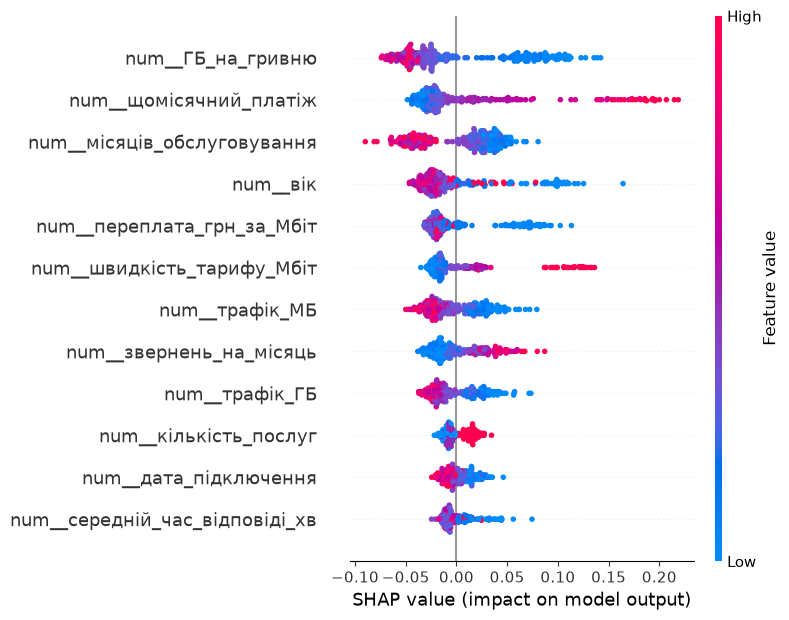

In [47]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names, max_display=12)

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

contrib = pd.Series(sv1[idx], index=feat_names)
top3 = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(3)
print('базовий рівень: %.3f' % np.ravel(expl.expected_value)[-1])
display(top3.to_frame('внесок'))
display(Xte.iloc[[idx]].T)

ризик клієнта: 0.877
базовий рівень: 0.258


,внесок
num__щомісячний_платіж,0.185070
num__швидкість_тарифу_Мбіт,0.120873
num__ГБ_на_гривню,0.104561


,544
вік,27.0
стать,ч
місто,дрогобич
тариф,максимальний
тип_підключення,оптика
спосіб_оплати,каса
автоплатіж,ні
кількість_послуг,3.0
місяців_обслуговування,11.0
швидкість_тарифу_Мбіт,1000.0


In [49]:
EXPLANATION_FOR_MANAGER = 'Клієнт у зоні найвищого ризику (≈88 %). Головні причини: він платить майже 700 грн на місяць — більш ніж удвічі більше за типового клієнта; при цьому користується інтернетом мало — за свої гроші отримує втричі менше трафіку, ніж зазвичай, тобто фактично переплачує за швидкість, яка йому не потрібна; і він молодий (27 років), а молоді клієнти найлегше змінюють провайдера. Що можна запропонувати: перехід на дешевший тариф, який відповідає його реальному споживанню.'
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Клієнт у зоні найвищого ризику (≈88 %). Головні причини: він платить майже 700 грн на місяць — більш ніж удвічі більше за типового клієнта; при цьому користується інтернетом мало — за свої гроші отримує втричі менше трафіку, ніж зазвичай, тобто фактично переплачує за швидкість, яка йому не потрібна; і він молодий (27 років), а молоді клієнти найлегше змінюють провайдера. Що можна запропонувати: перехід на дешевший тариф, який відповідає його реальному споживанню.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'ГБ_на_гривню'
SHAP_NOT_CAUSAL_WHY = 'у клієнта з найвищим ризиком ця ознака тягне ризик угору (0.16 ГБ/грн проти типових 0.51), і за перестановочною важливістю вона третя; але низьке споживання — це, найімовірніше, НАСЛІДОК того, що клієнт уже йде (підключився до іншого провайдера і користується ним, переїхав, рідко буває вдома), а не причина відтоку; змусити його качати більше гігабайтів (чи «підняти показник», знизивши ціну) не прибере справжньої причини — він однаково піде; SHAP каже лише, що модель використовує цю ознаку як сигнал, а не що зміна ознаки змінить результат'
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

ГБ_на_гривню — у клієнта з найвищим ризиком ця ознака тягне ризик угору (0.16 ГБ/грн проти типових 0.51), і за перестановочною важливістю вона третя; але низьке споживання — це, найімовірніше, НАСЛІДОК того, що клієнт уже йде (підключився до іншого провайдера і користується ним, переїхав, рідко буває вдома), а не причина відтоку; змусити його качати більше гігабайтів (чи «підняти показник», знизивши ціну) не прибере справжньої причини — він однаково піде; SHAP каже лише, що модель використовує цю ознаку як сигнал, а не що зміна ознаки змінить результат


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_МБ + трафік_ГБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",ГБ_на_гривню,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE = 'ознака переплата_грн_за_Мбіт, яку я сам сконструював у розділі 8 з гіпотезою «хто переплачує за швидкість — іде»: за вбудованою важливістю вона в топ-5 (0.063), і її легко прочитати як підтвердження гіпотези; але в сирих даних картина протилежна — найчастіше йдуть ті, хто платить НАЙМЕНШЕ за мегабіт (нижня чверть: 44 % відтоку проти 17–21 % у решти); до того ж ця ознака частково кодує артефакт збору: у підозрюваних філіях Ф-01 і Ф-02 медіанна ціна за Мбіт нижча (1.19 проти 1.48 грн), і серед клієнтів з найнижчою переплатою 46 % — із цих двох філій (загалом їх 31 %); тобто частина «впливу переплати» — це насправді «клієнт із Центру чи Заходу»; висновок: ні назва ознаки, ні її важливість не кажуть, у який бік і чому вона діє — це треба перевіряти по сирих даних і по джерелу'
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

ознака переплата_грн_за_Мбіт, яку я сам сконструював у розділі 8 з гіпотезою «хто переплачує за швидкість — іде»: за вбудованою важливістю вона в топ-5 (0.063), і її легко прочитати як підтвердження гіпотези; але в сирих даних картина протилежна — найчастіше йдуть ті, хто платить НАЙМЕНШЕ за мегабіт (нижня чверть: 44 % відтоку проти 17–21 % у решти); до того ж ця ознака частково кодує артефакт збору: у підозрюваних філіях Ф-01 і Ф-02 медіанна ціна за Мбіт нижча (1.19 проти 1.48 грн), і серед клієнтів з найнижчою переплатою 46 % — із цих двох філій (загалом їх 31 %); тобто частина «впливу переплати» — це насправді «клієнт із Центру чи Заходу»; висновок: ні назва ознаки, ні її важливість не кажуть, у який бік і чому вона діє — це треба перевіряти по сирих даних і по джерелу


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
TOP_N = 100
risk = model.predict_proba(Xte)[:, 1]
top = np.argsort(-risk)[:TOP_N]

hits = int(yte.values[top].sum())
base_rate = yte.mean()
random_hits = base_rate * TOP_N
lift = (hits / TOP_N) / base_rate

print('у перевірковій частині: %d клієнтів, пішли %d (%.1f %%)' % (len(yte), yte.sum(), base_rate * 100))
print('топ-%d за ризиком: пішли %d' % (TOP_N, hits))
print('100 навмання: пішли б ≈ %.0f' % random_hits)
print('lift = %.2f' % lift)

у перевірковій частині: 360 клієнтів, пішли 93 (25.8 %)
топ-100 за ризиком: пішли 59
100 навмання: пішли б ≈ 26
lift = 2.28


In [54]:
LIFT_MEANING = 'lift 2.25: зі 100 клієнтів, яких модель ставить на перше місце за ризиком, справді пішли 58 — а при обдзвоні 100 випадкових клієнтів відділ утримання натрапив би лише на ≈26; тобто за той самий тиждень роботи менеджери поговорять із удвічі більшою кількістю людей, яких справді треба утримувати'
assert LIFT_MEANING
print(LIFT_MEANING)

lift 2.25: зі 100 клієнтів, яких модель ставить на перше місце за ризиком, справді пішли 58 — а при обдзвоні 100 випадкових клієнтів відділ утримання натрапив би лише на ≈26; тобто за той самий тиждень роботи менеджери поговорять із удвічі більшою кількістю людей, яких справді треба утримувати


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_14.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [56]:
REPORT = '''
1. Метрика — AUC. Відтоку 25.8 %, тож модель «ніхто не піде» мала б точність 74.2 % і нульову користь: не знайшла б жодного клієнта, що йде; її AUC = 0.5, тобто марність видно одразу. AUC до того ж не залежить від порогу, який потім обирає бізнес.

2. Викинуто: id_клієнта — технічний номер, нічого не пояснює; дата_розірвання і код_причини_закриття — з'являються в момент розірвання договору, тобто після відтоку (заповнені рівно в 25.8 % рядків, показник детектора 1.000); оцінка_ризику_менеджером — ставить менеджер, що вже бачив поведінку клієнта (оцінка 5 → 99 % відтоку, сама дає AUC 0.945); філія — артефакт збору (п. 4). Детектор не знайшов оцінку менеджера: він перевіряє лише заповненість, а вона заповнена в усіх 1200 клієнтів — витік сидить у значеннях, а не в пропусках.

3. Чесне число: AUC 0.819 ± 0.022 (логістична регресія, 20 навчань). Драбина: 0.995 → 0.977 → 0.863 → 0.819. Розкид 0.022 у п'ять разів більший за різницю 0.004, тож дві такі моделі за середніми не відрізнити — потрібне парне порівняння на тих самих поділах.

4. Так. Відтік у Ф-01 Центр 46.5 % і Ф-02 Захід 38.2 % проти 17–21 % в інших філіях — сходинка, а не плавна зміна; за кварталами підключення сходинки немає (20–30 %). Без колонки філія ті самі ознаки вгадують «Центр/Захід» з AUC 0.700 — через платіж і швидкість. У новій філії моделі наосліп довіряти не можна: спершу перевірити якість на її даних.

5. Складніша модель дала більше: гістограмний бустинг +0.020 ± 0.009 над логістичною (значуще; ≈3.7 с проти ≈0.9 с на 20 навчань). Чотири сконструйовані «з голови» ознаки дали -0.0025 ± 0.0015 при тому самому часі. Але одна ознака з PDP — (вік − 48)² — дала логістичній +0.0385 ± 0.0075 (0.816 → 0.855), більше за перехід на бустинг, і без втрати швидкості.

6. код_тарифного_плану: за вбудованою важливістю 2-ге місце (0.096), перестановочна -0.0009. 40 рівнів → 40 колонок після кодування, і на кожній дерево може знайти розбиття, що на навчальних даних випадково зменшує неоднорідність (особливо на рідкісних кодах); 300 дерев підсумовують ці дрібні виграші. Вбудована важливість рахується на навчальних даних, тож міряє запам'ятовування, а не користь.

7. трафік_ГБ і трафік_МБ (|r| = 0.9997) у повній моделі: -0.0002 і +0.0027 — обидві «непотрібні». Без ГБ важливість МБ зросла до +0.0098. Перемішування однієї нічого не ламає, бо модель бере ту саму інформацію з другої. Це не вада: метод точно відповідає на питання «наскільки гірше без ЦІЄЇ ознаки, коли решта на місці»; хибний лише висновок «≈0, отже можна викинути обидві».

8. Вік: ризик 0.37 у 18 років, мінімум ≈0.23 у 40–55, знову 0.32 у 85 — U-форма. Логістична регресія без втручання не побачила б: один коефіцієнт дає лише монотонну залежність. З ознакою (вік − 48)² побачила: +0.0385 AUC.

9. Знижка: загальний PDP плаский (0.258 → 0.261), ніби знижка не діє. ICE: приблизно третина кривих іде вгору, п'ята — вниз. У сирих даних: стаж до 24 міс — відтік 27 % → 40 % при знижці 20 %; понад 24 міс — 21 % → 10 %. Протилежні ефекти погасили одне одного в середньому. Ліс цю взаємодію відтворив лише слабко (0.310→0.319 і 0.178→0.173) — питання до моделі, а не до PDP.

10. ГБ_на_гривню: у найризиковішого клієнта 0.16 проти типових 0.51, тягне ризик угору. Але мале споживання — найімовірніше наслідок того, що клієнт уже йде (користується іншим провайдером), а не причина. «Модель цим користується» означає: ознака — добрий сигнал; «це причина» означало б: змінимо ознаку — зміниться результат. Друге вимагає причинного висновку, якого дані не дають.

11. Список зі 100 найризиковіших: 58 справді пішли, навмання було б ≈26 — lift 2.25, тобто вдвічі більше корисних дзвінків за ті самі сили. Застереження: модель показує, кого обдзвонити, а не що пропонувати — знижка новачкам у даних іде разом із вищим відтоком, тож пропозицію треба перевірити на пілотній групі; і в Ф-01/Ф-02 якість треба звітувати окремо.

Декларація про використання ШІ:
Користувався ШІ-асистентом (Claude) як репетитором: для пояснення завдань і понять (AUC, витік, PDP, ICE, SHAP), для допомоги з кодом функцій to_number, build_X, make_pipe, leak_scan, paired та графіків, для перевірки ідей щодо пасток у даних. Самостійно: запускав ноутбук на своїх даних, звіряв усі числа у звіті з виводом комірок, розбирав код рядок за рядком, щоб могти його пояснити.
'''
print(REPORT)


1. Метрика — AUC. Відтоку 25.8 %, тож модель «ніхто не піде» мала б точність 74.2 % і нульову користь: не знайшла б жодного клієнта, що йде; її AUC = 0.5, тобто марність видно одразу. AUC до того ж не залежить від порогу, який потім обирає бізнес.

2. Викинуто: id_клієнта — технічний номер, нічого не пояснює; дата_розірвання і код_причини_закриття — з'являються в момент розірвання договору, тобто після відтоку (заповнені рівно в 25.8 % рядків, показник детектора 1.000); оцінка_ризику_менеджером — ставить менеджер, що вже бачив поведінку клієнта (оцінка 5 → 99 % відтоку, сама дає AUC 0.945); філія — артефакт збору (п. 4). Детектор не знайшов оцінку менеджера: він перевіряє лише заповненість, а вона заповнена в усіх 1200 клієнтів — витік сидить у значеннях, а не в пропусках.

3. Чесне число: AUC 0.819 ± 0.022 (логістична регресія, 20 навчань). Драбина: 0.995 → 0.977 → 0.863 → 0.819. Розкид 0.022 у п'ять разів більший за різницю 0.004, тож дві такі моделі за середніми не відрізнити — пот

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.